In [1]:
pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



--- FIRST FIVE ROWS ---
   Student_ID  Study_Hours  Attendance  Math_Score  Science_Score  \
0           1          2.0        65.0          55             60   
1           2          5.0        90.0          85             88   
2           3          3.0        75.0          65             70   
3           4          8.0        98.0          95             96   
4           5          6.0        85.0          80             82   

   English_Score  
0             58  
1             82  
2             68  
3             92  
4             84  

--- DATASET SHAPE ---
(16, 6)

--- COLUMN INFORMATION ---
<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Student_ID     16 non-null     int64  
 1   Study_Hours    15 non-null     float64
 2   Attendance     15 non-null     float64
 3   Math_Score     16 non-null     int64  
 4   Science_Score  16 non-null 

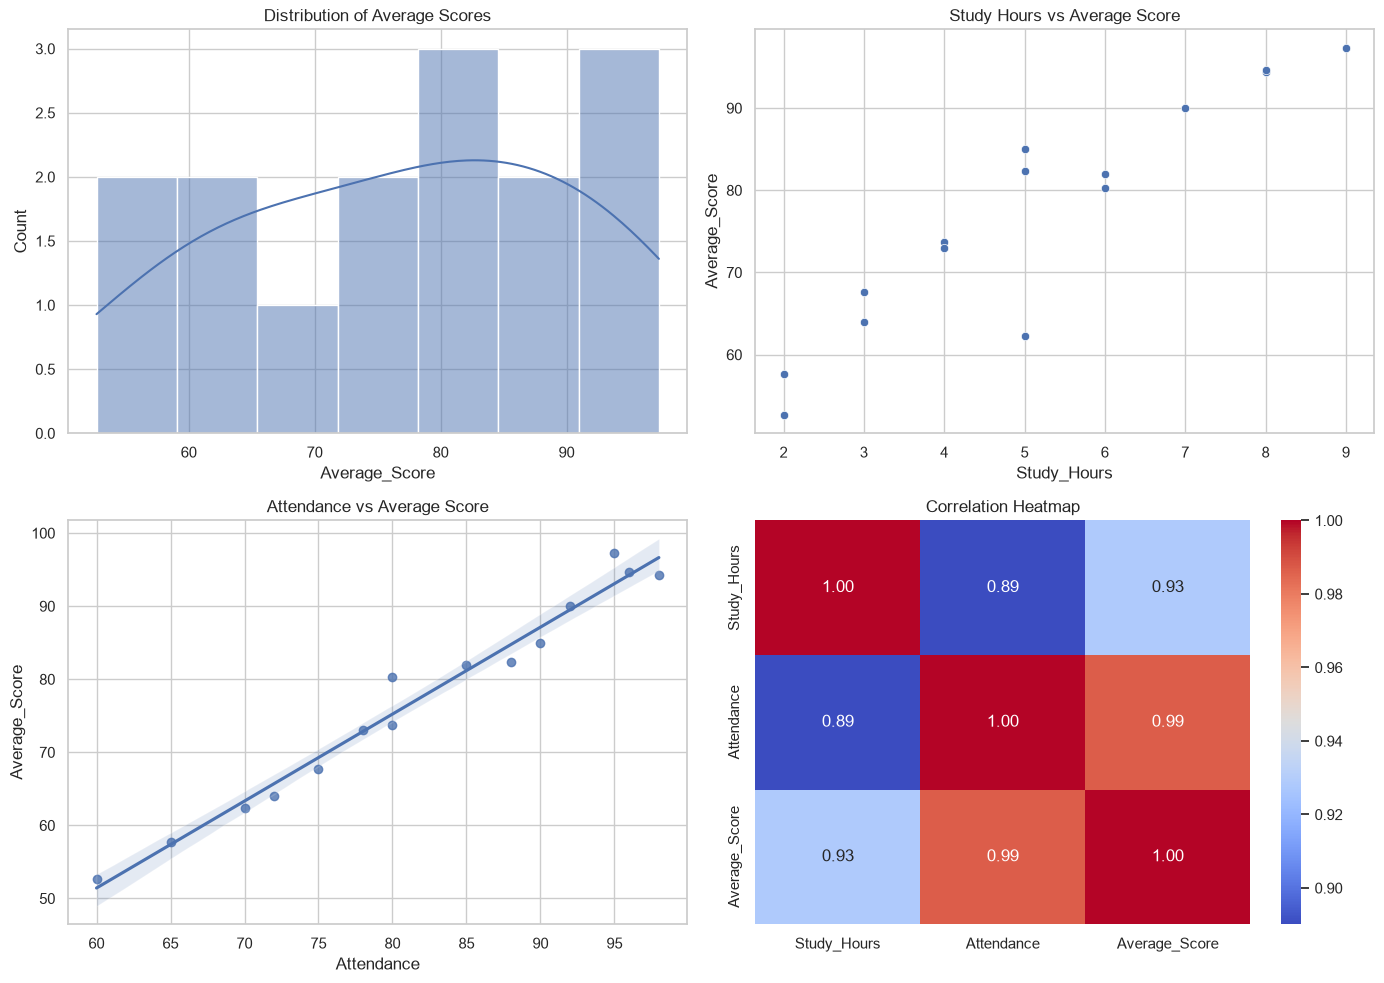


Analysis completed successfully!
Cleaned dataset saved.
Visualization saved as student_analysis.png


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create a sample dataset
data = {
    "Student_ID": range(1, 16),
    "Study_Hours": [
        2, 5, 3, 8, 6, np.nan, 4, 9, 7, 2, 5, 6, 8, 3, 4
    ],
    "Attendance": [
        65, 90, 75, 98, 85, 70, np.nan, 95, 92, 60,
        88, 80, 96, 72, 78
    ],
    "Math_Score": [
        55, 85, 65, 95, 80, 60, 72, 98, 90, 50,
        82, 78, 94, 62, 70
    ],
    "Science_Score": [
        60, 88, 70, 96, 82, 65, 75, 99, 91, 55,
        85, 80, 97, 66, 73
    ],
    "English_Score": [
        58, 82, 68, 92, 84, 62, 74, 95, 89, 53,
        80, 83, 93, 64, 76
    ]
}

df = pd.DataFrame(data)

# Add an intentional duplicate to demonstrate duplicate handling
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

# 2. Inspect the dataset
print("\n--- FIRST FIVE ROWS ---")
print(df.head())

print("\n--- DATASET SHAPE ---")
print(df.shape)

print("\n--- COLUMN INFORMATION ---")
df.info()

print("\n--- STATISTICAL SUMMARY ---")
print(df.describe())

# 3. Check and handle missing values
print("\n--- MISSING VALUES BEFORE CLEANING ---")
print(df.isnull().sum())

# Fill numerical missing values with column medians
numeric_cols = [
    "Study_Hours", "Attendance",
    "Math_Score", "Science_Score", "English_Score"
]

df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

# 4. Remove duplicate records
print("\nDuplicate rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

# 5. Feature engineering
df["Average_Score"] = df[
    ["Math_Score", "Science_Score", "English_Score"]
].mean(axis=1).round(2)

df["Performance"] = pd.cut(
    df["Average_Score"],
    bins=[-1, 59, 74, 89, 100],
    labels=["Needs Improvement", "Average", "Good", "Excellent"]
)

# 6. Filtering and sorting
print("\n--- STUDENTS WITH AVERAGE SCORE ABOVE 80 ---")
print(df[df["Average_Score"] > 80])

print("\n--- TOP FIVE STUDENTS ---")
print(df.sort_values(
    by="Average_Score", ascending=False
).head(5))

# 7. Grouping and aggregation
print("\n--- PERFORMANCE CATEGORY COUNTS ---")
print(df["Performance"].value_counts())

print("\n--- AVERAGE SCORE BY PERFORMANCE ---")
print(df.groupby(
    "Performance", observed=True
)["Average_Score"].mean())

# 8. Correlation analysis
print("\n--- CORRELATION MATRIX ---")
correlation = df[
    ["Study_Hours", "Attendance", "Average_Score"]
].corr()
print(correlation)

# 9. Data visualization
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Average score distribution
sns.histplot(
    data=df, x="Average_Score",
    bins=7, kde=True, ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Average Scores")

# Study hours vs average score
sns.scatterplot(
    data=df, x="Study_Hours", y="Average_Score",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Study Hours vs Average Score")

# Attendance vs average score
sns.regplot(
    data=df, x="Attendance", y="Average_Score",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Attendance vs Average Score")

# Correlation heatmap
sns.heatmap(
    correlation, annot=True, cmap="coolwarm",
    fmt=".2f", ax=axes[1, 1]
)
axes[1, 1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.savefig("student_analysis.png", dpi=300)
plt.show()

# 10. Export cleaned dataset
df.to_csv("cleaned_student_performance.csv", index=False)

print("\nAnalysis completed successfully!")
print("Cleaned dataset saved.")
print("Visualization saved as student_analysis.png")
